# Dataset A 

In [2]:
import json
from pathlib import Path
from collections import Counter
import pandas as pd

In [3]:
data_path = Path("dataset_a")

print(data_path.resolve())
print(data_path.exists())

C:\Users\HP\Downloads\imbesideyou\dataset_a
True


In [4]:
manifests = list(data_path.glob("**/gt_manifest.json"))

print("Number of manifests:", len(manifests))

Number of manifests: 63


In [5]:
sessions = list(data_path.iterdir())

session_count = 0
chunk_count = 0
event_count = 0

for session in sessions:
    if not session.is_dir():
        continue

    session_count += 1

    for chunk in session.iterdir():
        if not chunk.is_dir():
            continue

        if chunk.name.startswith("chunk_"):
            chunk_count += 1

            events_file = chunk / "events.jsonl"

            if events_file.exists():
                with open(events_file, "r", encoding="utf-8") as f:
                    event_count += sum(1 for _ in f)

print("Sessions:", session_count)
print("Chunks:", chunk_count)
print("Events:", event_count)

Sessions: 63
Chunks: 132
Events: 162768


In [6]:
event_types = Counter()

for session in data_path.iterdir():
    if not session.is_dir():
        continue

    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)
                event_types[event["event_type"]] += 1

event_type_table = pd.DataFrame(
    event_types.most_common(),
    columns=["event_type", "count"]
)

event_type_table

,event_type,count
0,app_switch,50588
1,keystroke,38717
2,screenshot_smart,34580
3,shortcut,13668
4,mouse_click,6177
5,browser_click,5365
6,clipboard_change,5198
7,mouse_scroll,3180
8,browser_form_input,1805
9,browser_navigation,1725


In [7]:
layers = Counter()

for session in data_path.iterdir():
    if not session.is_dir():
        continue

    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)
                layers[event["layer"]] += 1

layer_table = pd.DataFrame(
    layers.items(),
    columns=["layer", "count"]
)

layer_table

,layer,count
0,SYSTEM,454
1,L2,118399
2,L1,34580
3,L3,9335


In [8]:
applications = Counter()

for session in data_path.iterdir():
    if not session.is_dir():
        continue

    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)

                active_app = event.get("context", {}).get("active_app")

                if isinstance(active_app, dict):
                    app_name = active_app.get("app_name")
                else:
                    app_name = active_app

                if app_name:
                    applications[app_name] += 1

application_table = pd.DataFrame(
    applications.most_common(15),
    columns=["application", "count"]
)

application_table

,application,count
0,Google Chrome,118134
1,Notepad,30234
2,Microsoft Word,5365
3,Microsoft PowerPoint,3234
4,Windows Explorer,1948
5,WindowsTerminal,1687
6,Microsoft Excel,887
7,procmine-desktop-agent,320
8,olk,182
9,Settings,126


In [9]:
gt_process_count = Counter()
gt_variant_count = Counter()

for session in data_path.iterdir():
    if not session.is_dir():
        continue

    gt_file = session / "gt.jsonl"

    if not gt_file.exists():
        continue

    with open(gt_file, "r", encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)

            process = record.get("current_process")
            variant = record.get("process_variant")

            if process:
                gt_process_count[process] += 1

            if variant:
                gt_variant_count[variant] += 1

print("Ground-truth process LABEL records:")
print(gt_process_count)

print("\nGround-truth variant LABEL records:")
print(gt_variant_count)

Ground-truth process LABEL records:
Counter({'F': 996, 'A': 941, 'H': 859, 'C': 782, 'M': 761, 'K': 746, 'G': 725, 'L': 696, 'O': 650, 'E': 649, 'B': 640, 'J': 596, 'I': 572, 'N': 496, 'D': 437})

Ground-truth variant LABEL records:
Counter({'std': 1996, 'reg': 1611, 'exc': 687, 'adj': 450})


In [10]:
total_executions = 0

for manifest in manifests:
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    for process in data["processes"]:
        total_executions += len(process["executions"])

print("Total executions:", total_executions)

Total executions: 2009


In [11]:
execution_counts = Counter()

for manifest in manifests:
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    for process in data["processes"]:
        process_name = process["code"]
        execution_counts[process_name] += len(process["executions"])

execution_table = pd.DataFrame(
    execution_counts.most_common(),
    columns=["process", "executions"]
)

execution_table

,process,executions
0,F,169
1,C,161
2,A,159
3,M,155
4,H,147
5,G,144
6,L,137
7,N,129
8,K,127
9,B,126


In [12]:
process_variant_counts = Counter()

for manifest in manifests:
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    for process in data["processes"]:
        process_code = process["code"]

        for execution in process["executions"]:
            variant = execution["variant"]
            process_variant_counts[(process_code, variant)] += 1

process_variant_table = pd.DataFrame(
    [
        [process, variant, count]
        for (process, variant), count in process_variant_counts.items()
    ],
    columns=["process", "variant", "executions"]
).sort_values(
    ["process", "executions"],
    ascending=[True, False]
)

process_variant_table

,process,variant,executions
0,A,std,120
1,A,exc,39
2,B,reg,104
19,B,adj,22
3,C,NaN,161
11,D,NaN,114
4,E,NaN,111
12,F,std,123
13,F,exc,46
5,G,reg,117


In [13]:
execution_durations = []

for manifest in manifests:
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    for process in data["processes"]:
        process_code = process["code"]

        for execution in process["executions"]:
            start = pd.to_datetime(execution["start_ts"])
            end = pd.to_datetime(execution["end_ts"])

            duration_seconds = (end - start).total_seconds()

            execution_durations.append({
                "process": process_code,
                "variant": execution["variant"],
                "duration_seconds": duration_seconds
            })

duration_table = pd.DataFrame(execution_durations)

duration_table.describe()

,duration_seconds
count,1752.000000
mean,41.593886
std,40.786544
min,16.641227
25%,25.891799
50%,31.700105
75%,44.782320
max,1144.824536


In [14]:
max_execution = duration_table.loc[
    duration_table["duration_seconds"].idxmax()
]

max_execution

process                       M
variant                     NaN
duration_seconds    1144.824536
Name: 1173, dtype: object

In [16]:
process_duration_table = (
    duration_table
    .groupby("process")["duration_seconds"]
    .agg(
        executions="count",
        total_seconds="sum",
        average_seconds="mean",
        median_seconds="median"
    )
    .sort_values("total_seconds", ascending=False)
)

process_duration_table

,executions,total_seconds,average_seconds,median_seconds
process,,,,
I,104,8101.518140,77.899213,73.886532
M,141,7520.043265,53.333640,39.143148
C,138,6987.717033,50.635631,39.841825
N,109,5398.476765,49.527310,40.395456
F,151,5358.188228,35.484690,27.823599
B,114,4818.059765,42.263682,25.048209
A,146,4721.027044,32.335802,27.910860
L,122,4610.471154,37.790747,24.679608
D,95,4523.978700,47.620828,39.244675


In [17]:
continuation_counts = Counter()

for manifest in manifests:
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    for process in data["processes"]:
        for execution in process["executions"]:
            from_prev = execution.get("continues_from_prev", False)
            to_next = execution.get("continues_to_next", False)

            if from_prev and to_next:
                continuation_counts["continues_from_prev_and_to_next"] += 1
            elif from_prev:
                continuation_counts["continues_from_prev_only"] += 1
            elif to_next:
                continuation_counts["continues_to_next_only"] += 1
            else:
                continuation_counts["independent_execution"] += 1

continuation_table = pd.DataFrame(
    continuation_counts.items(),
    columns=["execution_type", "count"]
)

continuation_table

,execution_type,count
0,independent_execution,1946
1,continues_from_prev_and_to_next,63


In [18]:
process_continuation_counts = Counter()

for manifest in manifests:
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    for process in data["processes"]:
        process_code = process["code"]

        for execution in process["executions"]:
            from_prev = execution.get("continues_from_prev", False)
            to_next = execution.get("continues_to_next", False)

            if from_prev and to_next:
                process_continuation_counts[process_code] += 1

process_continuation_table = pd.DataFrame(
    process_continuation_counts.items(),
    columns=["process", "cross_chunk_executions"]
).sort_values(
    "cross_chunk_executions",
    ascending=False
)

process_continuation_table

,process,cross_chunk_executions
7,F,17
3,L,10
1,K,7
8,B,6
9,G,4
11,A,3
4,D,3
0,H,3
5,I,3
2,O,2


In [22]:
execution_activity = []

for manifest in manifests:
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    for process in data["processes"]:
        process_code = process["code"]

        for execution in process["executions"]:
            start = pd.to_datetime(execution["start_ts"])
            end = pd.to_datetime(execution["end_ts"])

            execution_activity.append({
                "process": process_code,
                "variant": execution.get("variant"),
                "duration_seconds": (end - start).total_seconds(),
                "seq": execution.get("seq")
            })

execution_activity_table = pd.DataFrame(execution_activity)

execution_activity_table.describe()

,duration_seconds,seq
count,1752.000000,2009.000000
mean,41.593886,2.297661
std,40.786544,1.064643
min,16.641227,1.000000
25%,25.891799,1.000000
50%,31.700105,2.000000
75%,44.782320,3.000000
max,1144.824536,5.000000


# Dataset A- screenshot


Total screenshots found: 6741

Screenshot: dataset_a\ses_20260701-172430-yuvraj\chunk_20260701-1700-yuvraj\screenshots\scr_smart_1782926671604_monitor_1_post.jpg


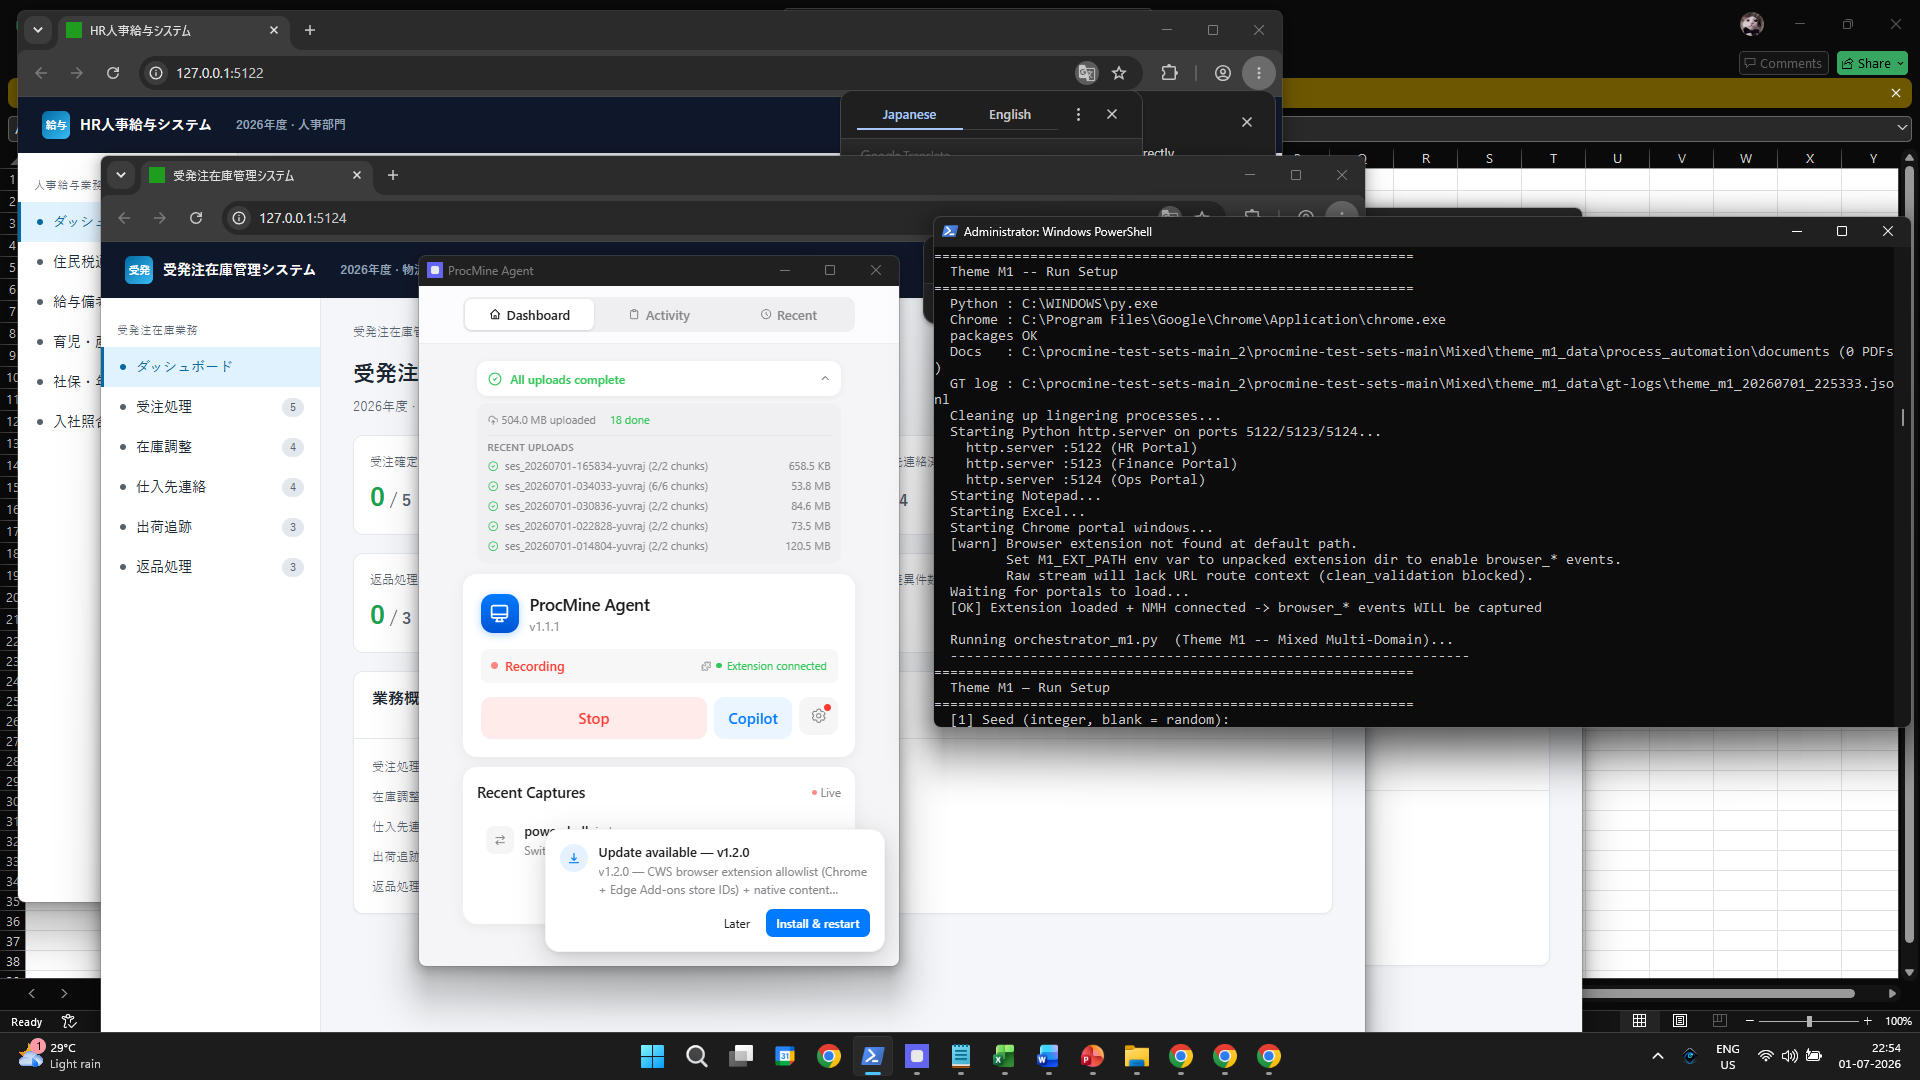


Screenshot: dataset_a\ses_20260701-172430-yuvraj\chunk_20260701-1700-yuvraj\screenshots\scr_smart_1782926730375_monitor_1_post.jpg


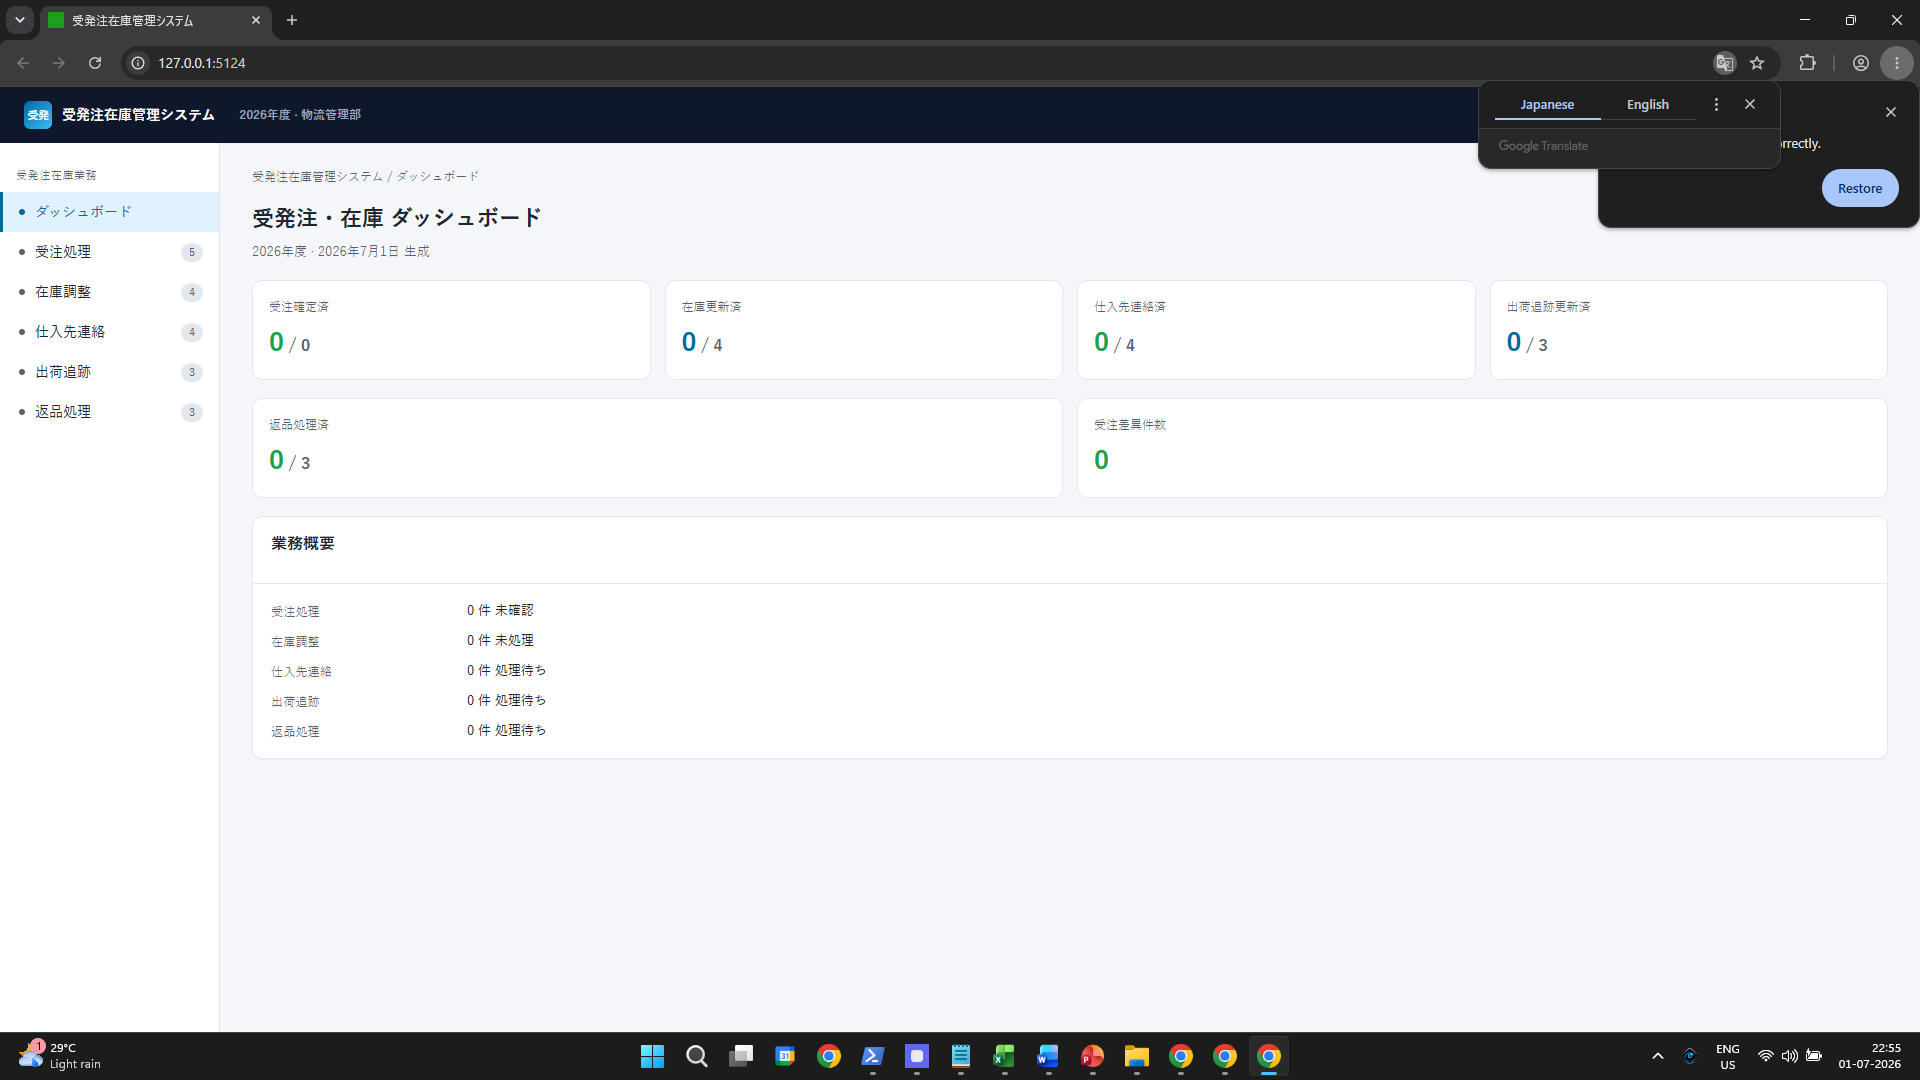


Screenshot: dataset_a\ses_20260701-172430-yuvraj\chunk_20260701-1700-yuvraj\screenshots\scr_smart_1782926731618_monitor_1_post.jpg


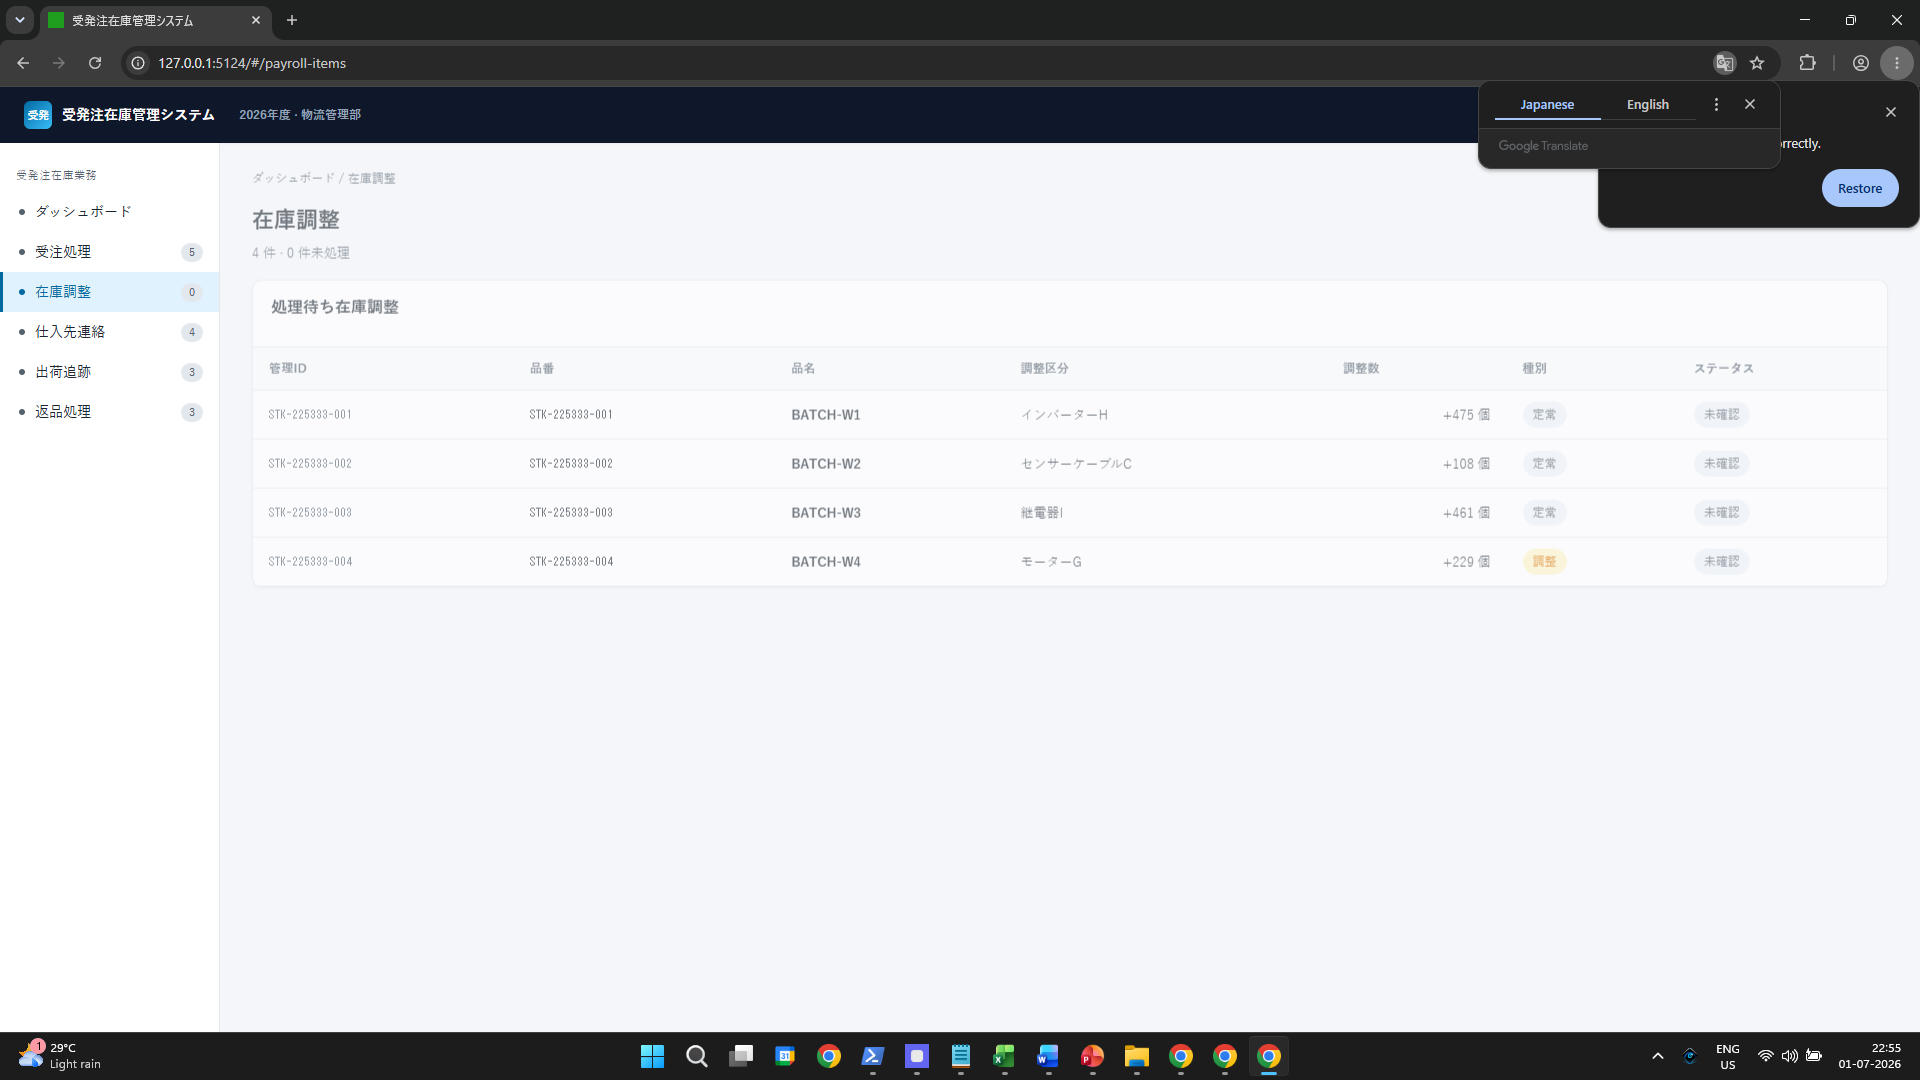

In [23]:
from PIL import Image
from IPython.display import display

screenshot_files = list(data_path.glob("**/screenshots/*.jpg"))

print("Total screenshots found:", len(screenshot_files))

for img_path in screenshot_files[:3]:
    print("\nScreenshot:", img_path)
    display(Image.open(img_path))

In [24]:
# Check screenshot events and extracted text in Dataset A

screenshot_events = 0
screenshots_with_text = 0
sample_text = []

for session in data_path.iterdir():
    if not session.is_dir():
        continue

    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)

                if event.get("event_type") == "screenshot_smart":
                    screenshot_events += 1

                    extracted_text = (
                        event.get("context", {})
                        .get("extracted_text")
                    )

                    if extracted_text:
                        screenshots_with_text += 1

                        if len(sample_text) < 5:
                            sample_text.append(extracted_text)

print("Screenshot events:", screenshot_events)
print("Screenshots with extracted text:", screenshots_with_text)

print("\nSample extracted text:")
for i, text in enumerate(sample_text, 1):
    print(f"\n--- Sample {i} ---")
    print(text)

Screenshot events: 34580
Screenshots with extracted text: 0

Sample extracted text:


In [25]:
# Compare time gaps:
# 1. inside a process execution
# 2. between two consecutive executions

within_execution_gaps = []
between_execution_gaps = []

for manifest in manifests:
    session_path = manifest.parent

    # Load ground truth manifest
    with open(manifest, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Collect executions
    executions = []

    for process in data["processes"]:
        for execution in process["executions"]:
            executions.append({
                "process": process["code"],
                "start": pd.to_datetime(execution["start_ts"]),
                "end": pd.to_datetime(execution["end_ts"])
            })

    # Sort executions by start time
    executions.sort(key=lambda x: x["start"])

    # Compare consecutive executions
    for i in range(1, len(executions)):
        gap = (
            executions[i]["start"] - executions[i - 1]["end"]
        ).total_seconds()

        if gap >= 0:
            between_execution_gaps.append(gap)

print("Number of gaps between executions:", len(between_execution_gaps))

print("\nBetween-execution gap statistics:")
print(
    pd.Series(
        between_execution_gaps,
        name="gap_seconds"
    ).describe()
)

Number of gaps between executions: 1689

Between-execution gap statistics:
count    1689.000000
mean        1.193641
std         7.799742
min         0.000000
25%         0.000882
50%         0.001542
75%         0.003018
max       120.975455
Name: gap_seconds, dtype: float64


# Dataset -B 

In [16]:
data_path_b = Path("dataset_b")

sessions_b = [
    p for p in data_path_b.iterdir()
    if p.is_dir()
]

chunk_count_b = 0
event_count_b = 0

for session in sessions_b:
    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        chunk_count_b += 1

        events_file = chunk / "events.jsonl"

        if events_file.exists():
            with open(events_file, "r", encoding="utf-8") as f:
                event_count_b += sum(1 for _ in f)

print("Dataset B")
print("Sessions:", len(sessions_b))
print("Chunks:", chunk_count_b)
print("Events:", event_count_b)

Dataset B
Sessions: 15
Chunks: 20
Events: 20477


In [17]:
event_types_b = Counter()

for session in sessions_b:
    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)
                event_types_b[event.get("event_type")] += 1

event_type_table_b = pd.DataFrame(
    event_types_b.most_common(),
    columns=["event_type", "count"]
)

event_type_table_b

,event_type,count
0,screenshot_smart,4759
1,keystroke,4678
2,mouse_click,2133
3,browser_click,1914
4,mouse_scroll,1724
5,app_switch,1654
6,shortcut,1386
7,clipboard_change,872
8,browser_form_input,608
9,browser_navigation,204


In [18]:
applications_b = Counter()

for session in sessions_b:
    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)

                active_app = event.get("context", {}).get("active_app")

                if isinstance(active_app, dict):
                    app_name = active_app.get("app_name")
                else:
                    app_name = active_app

                if app_name:
                    applications_b[app_name] += 1

application_table_b = pd.DataFrame(
    applications_b.most_common(),
    columns=["application", "count"]
)

application_table_b

,application,count
0,Microsoft Edge,13300
1,Microsoft Word,3704
2,Microsoft Excel,1201
3,OpenWith,757
4,Notepad,599
5,WindowsTerminal,407
6,procmine-desktop-agent,205
7,Windows Explorer,78
8,ms-teams,73
9,prl_cc,28


In [19]:
session_durations_b = []

for session in sessions_b:
    session_start = None
    session_end = None

    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)

                timestamp = pd.to_datetime(event["timestamp_iso"])

                if session_start is None or timestamp < session_start:
                    session_start = timestamp

                if session_end is None or timestamp > session_end:
                    session_end = timestamp

    if session_start is not None and session_end is not None:
        duration = (session_end - session_start).total_seconds()

        session_durations_b.append({
            "session": session.name,
            "duration_seconds": duration
        })

session_duration_table_b = pd.DataFrame(session_durations_b)

session_duration_table_b

,session,duration_seconds
0,ses_20260701-164424-CHAITANYA0BCF,682.956
1,ses_20260701-171614-CHAITANYA0BCF,838.663
2,ses_20260701-173246-SIDDHIGUPTAB00B,767.418
3,ses_20260701-173642-NEELA9BAF,620.935
4,ses_20260701-175258-LAPTOP-76QMG9DE,817.990
5,ses_20260701-175747-SIDDHIGUPTAB00B,690.786
6,ses_20260701-180923-NEELA9BAF,759.862
7,ses_20260701-181413-LAPTOP-76QMG9DE,785.262
8,ses_20260701-181913-SIDDHIGUPTAB00B,616.118
9,ses_20260701-182634-NEELA9BAF,631.434


In [20]:
session_event_counts_b = []

for session in sessions_b:
    event_count = 0

    for chunk in session.iterdir():
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            event_count += sum(1 for _ in f)

    session_event_counts_b.append({
        "session": session.name,
        "event_count": event_count
    })

session_event_table_b = pd.DataFrame(session_event_counts_b)

session_event_table_b

,session,event_count
0,ses_20260701-164424-CHAITANYA0BCF,1613
1,ses_20260701-171614-CHAITANYA0BCF,2015
2,ses_20260701-173246-SIDDHIGUPTAB00B,1439
3,ses_20260701-173642-NEELA9BAF,1136
4,ses_20260701-175258-LAPTOP-76QMG9DE,1550
5,ses_20260701-175747-SIDDHIGUPTAB00B,1309
6,ses_20260701-180923-NEELA9BAF,1349
7,ses_20260701-181413-LAPTOP-76QMG9DE,1518
8,ses_20260701-181913-SIDDHIGUPTAB00B,1165
9,ses_20260701-182634-NEELA9BAF,1001


In [21]:
# Look at the first 30 events of the first Dataset B session

session = sessions_b[0]
events = []

for chunk in sorted(session.iterdir()):
    if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
        continue

    events_file = chunk / "events.jsonl"

    if not events_file.exists():
        continue

    with open(events_file, "r", encoding="utf-8") as f:
        for line in f:
            event = json.loads(line)

            active_app = event.get("context", {}).get("active_app")

            if isinstance(active_app, dict):
                app_name = active_app.get("app_name")
            else:
                app_name = active_app

            events.append({
                "timestamp": event.get("timestamp_iso"),
                "event_type": event.get("event_type"),
                "application": app_name
            })

events_b_table = pd.DataFrame(events)

events_b_table.head(30)

,timestamp,event_type,application
0,2026-07-01T16:44:24.390Z,session_start,NaN
1,2026-07-01T16:44:24.950Z,app_switch,WindowsTerminal
2,2026-07-01T16:44:24.999Z,screenshot_smart,WindowsTerminal
3,2026-07-01T16:44:24.919Z,mouse_click,WindowsTerminal
4,2026-07-01T16:44:25.953Z,keystroke,WindowsTerminal
5,2026-07-01T16:44:26.054Z,keystroke,WindowsTerminal
6,2026-07-01T16:44:25.996Z,screenshot_smart,WindowsTerminal
7,2026-07-01T16:44:32.083Z,app_switch,Microsoft Edge
8,2026-07-01T16:44:32.183Z,window_state_change,Microsoft Edge
9,2026-07-01T16:44:34.213Z,app_switch,Microsoft Edge


In [22]:
id_gap = []

for session in sessions_b:
    session_events = []

    for chunk in sorted(session.iterdir()):
        if not chunk.is_dir() or not chunk.name.startswith("chunk_"):
            continue

        events_file = chunk / "events.jsonl"

        if not events_file.exists():
            continue

        with open(events_file, "r", encoding="utf-8") as f:
            for line in f:
                event = json.loads(line)
                session_events.append(event)

    session_events.sort(key=lambda x: x["timestamp_ms"])

    for i in range(1, len(session_events)):
        gap = (
            session_events[i]["timestamp_ms"]
            - session_events[i - 1]["timestamp_ms"]
        ) / 1000

        id_gap.append(gap)

gap_table_b = pd.Series(id_gap, name="gap_seconds").describe()

gap_table_b

count    20462.000000
mean         0.516803
std          1.277981
min          0.000000
25%          0.005000
50%          0.062000
75%          0.373000
max         64.117000
Name: gap_seconds, dtype: float64